# DeepFashion2 — Exact Kaggle Dataset
## EDA + Data Cleaning + Feature Engineering

This notebook is specifically built for the **exact Kaggle dataset requested for the project**:

**`thusharanair/deepfashion2-original-with-dataframes`**

Kaggle dataset:
https://www.kaggle.com/datasets/thusharanair/deepfashion2-original-with-dataframes

### Important
This notebook does **not** ask you to point to a random DeepFashion2 folder.

It downloads the exact Kaggle dataset by its dataset slug:

```text
thusharanair/deepfashion2-original-with-dataframes
```

Then it inspects the files that actually came with that Kaggle dataset before choosing the dataframe.

The notebook is designed for **Google Colab or Kaggle Notebook**.


## Project pipeline

For your PRD, the data pipeline is:

```text
Exact DeepFashion2 Kaggle dataset
            ↓
        EDA
            ↓
     Data cleaning
            ↓
   Feature engineering
            ↓
   Clean item metadata
            ↓
 Bounding-box garment crops
            ↓
       CLIP later
            ↓
     512-D embeddings
            ↓
         FAISS
```

Your PRD specifies DeepFashion2 as the fixed primary dataset and uses item-level annotations such as category and bounding boxes for the retrieval pipeline. It also targets a reproducible working subset of roughly 50,000 item crops for the deployed demo.


In [2]:
# ==============================
# 1. INSTALL / IMPORT LIBRARIES
# ==============================

# kagglehub lets us download the exact Kaggle dataset using its dataset slug.
!pip -q install -U kagglehub

import os
import glob
import json
import ast
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 100)

print("Libraries loaded successfully.")


Libraries loaded successfully.


# 2. DOWNLOAD THE EXACT KAGGLE DATASET

### Dataset slug

```text
thusharanair/deepfashion2-original-with-dataframes
```

This is the important part.

We are **not** downloading another DeepFashion2 dataset or a resized version.

The `dataset_download()` call uses the exact Kaggle dataset slug above.


In [1]:
# Download the EXACT requested Kaggle dataset

import kagglehub

KAGGLE_DATASET = "thusharanair/deepfashion2-original-with-dataframes"

print("Downloading:")
print(KAGGLE_DATASET)
print()

DATASET_PATH = kagglehub.dataset_download(KAGGLE_DATASET)

print("Dataset downloaded successfully!")
print("Local dataset path:")
print(DATASET_PATH)


Downloading:
thusharanair/deepfashion2-original-with-dataframes



100%|██████████| 14.9G/14.9G [06:37<00:00, 40.2MB/s]

Extracting files...


Dataset downloaded successfully!
Local dataset path:
/root/.cache/kagglehub/datasets/thusharanair/deepfashion2-original-with-dataframes/versions/2


## 3. Inspect the downloaded dataset

Before choosing any dataframe, we will list the files that were actually downloaded.

This is important because we should not guess the filename or column names.


In [3]:
# List all files in the exact downloaded Kaggle dataset

all_files = []

for root, dirs, files in os.walk(DATASET_PATH):
    for file in files:
        full_path = os.path.join(root, file)
        all_files.append(full_path)

all_files = sorted(all_files)

print("Total files found:", len(all_files))
print()

for i, file in enumerate(all_files[:100]):
    relative = os.path.relpath(file, DATASET_PATH)
    print(f"{i}: {relative}")

if len(all_files) > 100:
    print()
    print("Only the first 100 files are shown.")


Total files found: 510870

0: DeepFashion2/deepfashion2_original_images/test/json_for_test/keypoints_test_information.json
1: DeepFashion2/deepfashion2_original_images/test/json_for_test/retrieval_test_consumer_information.json
2: DeepFashion2/deepfashion2_original_images/test/json_for_test/retrieval_test_shop_information.json
3: DeepFashion2/deepfashion2_original_images/test/test/image/000001.jpg
4: DeepFashion2/deepfashion2_original_images/test/test/image/000002.jpg
5: DeepFashion2/deepfashion2_original_images/test/test/image/000003.jpg
6: DeepFashion2/deepfashion2_original_images/test/test/image/000004.jpg
7: DeepFashion2/deepfashion2_original_images/test/test/image/000005.jpg
8: DeepFashion2/deepfashion2_original_images/test/test/image/000006.jpg
9: DeepFashion2/deepfashion2_original_images/test/test/image/000007.jpg
10: DeepFashion2/deepfashion2_original_images/test/test/image/000008.jpg
11: DeepFashion2/deepfashion2_original_images/test/test/image/000009.jpg
12: DeepFashion2/deep

# 4. FIND THE DATAFRAME FILES

The Kaggle dataset is specifically the **"with dataframes"** version.

We will search the downloaded dataset for:

- CSV
- Parquet
- Excel

Then we will inspect the available dataframe files before selecting one.


In [4]:
# Find dataframe files ONLY inside the exact Kaggle dataset

dataframe_files = [
    f for f in all_files
    if Path(f).suffix.lower() in [".csv", ".parquet", ".xlsx", ".xls"]
]

print("Dataframe files found:", len(dataframe_files))
print()

for i, file in enumerate(dataframe_files):
    print(f"{i}: {os.path.relpath(file, DATASET_PATH)}")


Dataframe files found: 3

0: DeepFashion2/img_info_dataframes/test.csv
1: DeepFashion2/img_info_dataframes/train.csv
2: DeepFashion2/img_info_dataframes/validation.csv


## 5. Preview every dataframe file

If there are multiple CSV files, this cell shows:

- filename
- number of rows
- number of columns
- first few column names

This lets us choose the correct item-level dataframe based on the actual downloaded dataset.


In [5]:
def read_table(path, nrows=None):
    ext = Path(path).suffix.lower()

    if ext == ".csv":
        return pd.read_csv(path, nrows=nrows)
    elif ext == ".parquet":
        return pd.read_parquet(path)
    elif ext in [".xlsx", ".xls"]:
        return pd.read_excel(path, nrows=nrows)
    else:
        raise ValueError(f"Unsupported format: {ext}")


file_summary = []

for file in dataframe_files:
    try:
        preview = read_table(file, nrows=5)
        file_summary.append({
            "file": os.path.relpath(file, DATASET_PATH),
            "columns": preview.shape[1],
            "column_names": list(preview.columns),
        })
    except Exception as e:
        file_summary.append({
            "file": os.path.relpath(file, DATASET_PATH),
            "columns": "ERROR",
            "column_names": str(e),
        })

display(pd.DataFrame(file_summary))


,file,columns,column_names
0,DeepFashion2/img_info_dataframes/test.csv,3,"[path, img_height, img_width]"
1,DeepFashion2/img_info_dataframes/train.csv,12,"[path, segmentation, landmarks, b_box, category_id, category_name, scale, viewpoint, occlusion, ..."
2,DeepFashion2/img_info_dataframes/validation.csv,12,"[path, segmentation, landmarks, b_box, category_id, category_name, scale, viewpoint, occlusion, ..."


# 6. SELECT THE DATAFRAME

### Default behavior

The notebook tries to identify the most useful dataframe automatically by looking for columns containing terms such as:

- category
- bbox / bounding box
- image
- item
- source
- pair
- style

If several files look relevant, the notebook prints them and you can select the correct one manually.


In [6]:
def score_dataframe_columns(columns):
    text = " ".join(str(c).lower() for c in columns)

    keywords = [
        "category",
        "bbox",
        "bounding",
        "image",
        "item",
        "source",
        "pair",
        "style",
        "occlusion",
        "viewpoint",
        "scale",
    ]

    return sum(keyword in text for keyword in keywords)


if len(dataframe_files) == 0:
    raise FileNotFoundError(
        "The exact Kaggle dataset was downloaded, but no CSV/Parquet/Excel dataframe was found inside it."
    )

scores = []

for file in dataframe_files:
    try:
        preview = read_table(file, nrows=5)
        score = score_dataframe_columns(preview.columns)
        scores.append((score, file, list(preview.columns)))
    except Exception:
        pass

scores = sorted(scores, key=lambda x: x[0], reverse=True)

print("Candidate dataframes ranked by DeepFashion2-related columns:")
print()

for rank, (score, file, columns) in enumerate(scores, start=1):
    print(f"Rank {rank} | score={score}")
    print("File:", os.path.relpath(file, DATASET_PATH))
    print("Columns:", columns)
    print()

# Best candidate
BEST_INDEX = 0

if len(scores) == 0:
    raise RuntimeError("No readable dataframe was found.")

DATA_FILE = scores[BEST_INDEX][1]

print("Selected dataframe:")
print(DATA_FILE)


Candidate dataframes ranked by DeepFashion2-related columns:

Rank 1 | score=4
File: DeepFashion2/img_info_dataframes/train.csv
Columns: ['path', 'segmentation', 'landmarks', 'b_box', 'category_id', 'category_name', 'scale', 'viewpoint', 'occlusion', 'zoom_in', 'img_height', 'img_width']

Rank 2 | score=4
File: DeepFashion2/img_info_dataframes/validation.csv
Columns: ['path', 'segmentation', 'landmarks', 'b_box', 'category_id', 'category_name', 'scale', 'viewpoint', 'occlusion', 'zoom_in', 'img_height', 'img_width']

Rank 3 | score=0
File: DeepFashion2/img_info_dataframes/test.csv
Columns: ['path', 'img_height', 'img_width']

Selected dataframe:
/root/.cache/kagglehub/datasets/thusharanair/deepfashion2-original-with-dataframes/versions/2/DeepFashion2/img_info_dataframes/train.csv


### If the selected dataframe is not the one you want

Change:

```python
BEST_INDEX = 0
```

to:

```python
BEST_INDEX = 1
```

or another number based on the ranked list above.

**Do not change the Kaggle dataset slug.** We want the exact dataset requested.


In [7]:
# 7. LOAD THE SELECTED DATAFRAME

df = read_table(DATA_FILE)

print("Dataset loaded successfully!")
print()
print("Exact Kaggle dataset:")
print(KAGGLE_DATASET)
print()
print("Selected dataframe:")
print(os.path.relpath(DATA_FILE, DATASET_PATH))
print()
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])


Dataset loaded successfully!

Exact Kaggle dataset:
thusharanair/deepfashion2-original-with-dataframes

Selected dataframe:
DeepFashion2/img_info_dataframes/train.csv

Rows: 312186
Columns: 12


# PART A — UNDERSTAND THE DATA

Before cleaning anything, we first understand exactly what the dataframe contains.


In [8]:
# First 10 rows
display(df.head(10))


,path,segmentation,landmarks,b_box,category_id,category_name,scale,viewpoint,occlusion,zoom_in,img_height,img_width
0,/kaggle/input/deepfashion2-original-with-dataframes/DeepFashion2/deepfashion2_original_images/tr...,"[[360, 172, 364, 166, 371, 163, 325, 168, 299, 202, 279, 234, 258, 263, 233, 299, 256, 311, 273,...","[387, 176, 1, 371, 163, 1, 364, 166, 1, 360, 172, 2, 409, 188, 2, 410, 182, 2, 325, 168, 1, 299,...","[227, 155, 442, 381]",4,long sleeve outwear,2,2,2,1,640,640
1,/kaggle/input/deepfashion2-original-with-dataframes/DeepFashion2/deepfashion2_original_images/tr...,"[[381, 306, 334, 289, 297, 266, 261, 350, 225, 451, 216, 482, 268, 501, 273, 465, 312, 368, 279,...","[297, 266, 1, 334, 289, 1, 381, 306, 1, 261, 350, 2, 225, 451, 2, 216, 482, 2, 268, 501, 2, 273,...","[209, 263, 387, 539]",8,trousers,2,2,2,1,640,640
2,/kaggle/input/deepfashion2-original-with-dataframes/DeepFashion2/deepfashion2_original_images/tr...,"[[320, 33, 309, 86, 247, 102, 183, 78, 172, 27, 105, 45, 59, 80, 10, 125, 61, 175, 83, 161, 105,...","[241, 45, 2, 172, 27, 2, 183, 78, 2, 247, 102, 2, 309, 86, 2, 320, 33, 2, 105, 45, 2, 59, 80, 2,...","[6, 17, 460, 341]",1,short sleeve top,3,1,1,1,631,468
3,/kaggle/input/deepfashion2-original-with-dataframes/DeepFashion2/deepfashion2_original_images/tr...,"[[150, 285, 249, 302, 350, 270, 464, 396, 464, 588, 220, 630, 2, 563, 3, 374, 150, 285]]","[150, 285, 2, 249, 302, 2, 350, 270, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]","[0, 263, 465, 630]",9,skirt,3,1,1,3,631,468
4,/kaggle/input/deepfashion2-original-with-dataframes/DeepFashion2/deepfashion2_original_images/tr...,"[[351, 246, 353, 277, 325, 297, 279, 302, 242, 287, 182, 355, 212, 420, 210, 493, 290, 470, 272,...","[298, 270, 1, 242, 287, 2, 279, 302, 2, 325, 297, 2, 353, 277, 2, 351, 246, 1, 182, 355, 2, 212,...","[178, 182, 695, 800]",10,short sleeve dress,3,2,2,1,926,750
5,/kaggle/input/deepfashion2-original-with-dataframes/DeepFashion2/deepfashion2_original_images/tr...,"[[408, 304, 325, 322, 232, 300, 222, 387, 237, 466, 325, 473, 312, 434, 339, 495, 432, 482, 427,...","[232, 300, 1, 325, 322, 2, 408, 304, 1, 222, 387, 2, 237, 466, 2, 325, 473, 2, 312, 434, 1, 339,...","[218, 291, 435, 509]",7,shorts,2,2,2,1,520,750
6,/kaggle/input/deepfashion2-original-with-dataframes/DeepFashion2/deepfashion2_original_images/tr...,"[[273, 41, 273, 84, 314, 118, 369, 84, 390, 31, 414, 34, 398, 171, 389, 248, 388, 313, 312, 319,...","[318, 95, 1, 273, 41, 1, 273, 84, 2, 314, 118, 2, 369, 84, 2, 390, 31, 1, 251, 43, 1, 245, 151, ...","[230, 24, 431, 325]",5,vest,2,2,2,1,520,750
7,/kaggle/input/deepfashion2-original-with-dataframes/DeepFashion2/deepfashion2_original_images/tr...,"[[384, 170, 345, 257, 343, 352, 419, 292, 464, 218, 495, 259, 443, 329, 413, 365, 392, 406, 349,...","[414, 234, 1, 384, 170, 2, 345, 257, 2, 343, 352, 1, 419, 292, 1, 464, 218, 1, 361, 162, 2, 313,...","[113, 158, 502, 604]",12,vest dress,2,2,2,1,700,700
8,/kaggle/input/deepfashion2-original-with-dataframes/DeepFashion2/deepfashion2_original_images/tr...,"[[212, 305, 215, 346, 199, 382, 154, 336, 116, 295, 11, 378, 1, 502, 3, 622, 50, 621, 59, 580, 6...","[99, 267, 1, 116, 295, 2, 154, 336, 2, 199, 382, 2, 215, 346, 2, 212, 305, 1, 11, 378, 2, 0, 0, ...","[0, 265, 305, 623]",1,short sleeve top,2,2,2,2,624,468
9,/kaggle/input/deepfashion2-original-with-dataframes/DeepFashion2/deepfashion2_original_images/tr...,"[[271, 501, 319, 507, 354, 508, 375, 575, 373, 645, 308, 647, 246, 633, 255, 562, 271, 501]]","[271, 501, 1, 319, 507, 2, 354, 508, 2, 255, 562, 1, 246, 633, 2, 308, 647, 2, 373, 645, 2, 375,...","[242, 499, 376, 650]",9,skirt,1,2,2,1,959,640


In [9]:
# All column names

print("Columns:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")


Columns:
1. path
2. segmentation
3. landmarks
4. b_box
5. category_id
6. category_name
7. scale
8. viewpoint
9. occlusion
10. zoom_in
11. img_height
12. img_width


In [10]:
# Data types

display(df.dtypes.to_frame("data_type"))


,data_type
path,object
segmentation,object
landmarks,object
b_box,object
category_id,int64
category_name,object
scale,int64
viewpoint,int64
occlusion,int64
zoom_in,int64


In [11]:
# Dataset size

print("Rows:", len(df))
print("Columns:", len(df.columns))
print()
print("Memory usage:")
print(f"{df.memory_usage(deep=True).sum() / (1024**2):.2f} MB")


Rows: 312186
Columns: 12

Memory usage:
336.85 MB


In [12]:
# Statistical summary

display(df.describe(include="all").T)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
path,312186,191961,/kaggle/input/deepfashion2-original-with-dataframes/DeepFashion2/deepfashion2_original_images/tr...,8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
segmentation,312186,312184,"[[320, 217, 211, 218, 108, 202, 21, 402, 3, 625, 119, 623, 193, 403, 299, 624, 409, 624, 412, 39...",2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
landmarks,312186,310954,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",964,NaN,NaN,NaN,NaN,NaN,NaN,NaN
b_box,312186,304507,"[0, 0, 467, 623]",582,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category_id,312186.0,NaN,NaN,NaN,5.85359,3.758177,1.0,2.0,7.0,9.0,13.0
category_name,312186,13,short sleeve top,71645,NaN,NaN,NaN,NaN,NaN,NaN,NaN
scale,312186.0,NaN,NaN,NaN,1.992617,0.704964,1.0,1.0,2.0,2.0,3.0
viewpoint,312186.0,NaN,NaN,NaN,2.071678,0.460225,1.0,2.0,2.0,2.0,3.0
occlusion,312186.0,NaN,NaN,NaN,1.597439,0.605595,1.0,1.0,2.0,2.0,3.0
zoom_in,312186.0,NaN,NaN,NaN,1.429042,0.678629,1.0,1.0,1.0,2.0,3.0


# PART B — EDA

EDA = **Exploratory Data Analysis**

Here we are asking:

> "What is inside this exact DeepFashion2 dataframe?"


In [13]:
# Missing-value analysis

missing_count = df.isnull().sum()
missing_percent = (missing_count / len(df) * 100).round(2)

missing_table = pd.DataFrame({
    "missing_count": missing_count,
    "missing_percent": missing_percent
}).sort_values("missing_count", ascending=False)

display(missing_table[missing_table["missing_count"] > 0])


,missing_count,missing_percent


In [14]:
# Duplicate rows

duplicates = df.duplicated().sum()

print("Exact duplicate rows:", duplicates)
print("Duplicate percentage:", round(duplicates / len(df) * 100, 2), "%")


Exact duplicate rows: 0
Duplicate percentage: 0.0 %


## Automatically find important DeepFashion2 columns

We inspect the actual dataframe and try to identify the fields we need.

**We do not assume the column names.**


In [15]:
def find_column(columns, candidates):
    lower_map = {
        str(c).lower().strip(): c
        for c in columns
    }

    # Exact match
    for candidate in candidates:
        if candidate.lower() in lower_map:
            return lower_map[candidate.lower()]

    # Partial match
    for c in columns:
        c_lower = str(c).lower()
        for candidate in candidates:
            if candidate.lower() in c_lower:
                return c

    return None


COLUMN_CANDIDATES = {
    "item_id": [
        "item_id", "itemid", "item", "item_no",
        "item_number", "id"
    ],
    "image_id": [
        "image_id", "imageid", "img_id",
        "imgid", "image"
    ],
    "image_path": [
        "image_path", "imagepath", "img_path",
        "filepath", "file_path", "path", "filename"
    ],
    "category": [
        "category", "category_name", "class",
        "class_name", "categoryname"
    ],
    "category_id": [
        "category_id", "categoryid", "class_id"
    ],
    "source": [
        "source"
    ],
    "pair_id": [
        "pair_id", "pairid"
    ],
    "style": [
        "style", "style_id", "styleid"
    ],
    "scale": [
        "scale"
    ],
    "occlusion": [
        "occlusion"
    ],
    "viewpoint": [
        "viewpoint", "view"
    ],
}

detected = {}

for key, candidates in COLUMN_CANDIDATES.items():
    detected[key] = find_column(df.columns, candidates)

display(
    pd.DataFrame({
        "our_field": list(detected.keys()),
        "actual_dataframe_column": list(detected.values())
    })
)


,our_field,actual_dataframe_column
0,item_id,category_id
1,image_id,None
2,image_path,path
3,category,category_name
4,category_id,category_id
5,source,None
6,pair_id,None
7,style,None
8,scale,scale
9,occlusion,occlusion


## Category distribution

This is one of the most useful EDA plots for your project.

We want to see whether some clothing categories are much more common than others.


,count
category_name,
short sleeve top,71645
trousers,55387
shorts,36616
long sleeve top,36064
skirt,30835
vest dress,17949
short sleeve dress,17211
vest,16095
long sleeve outwear,13457


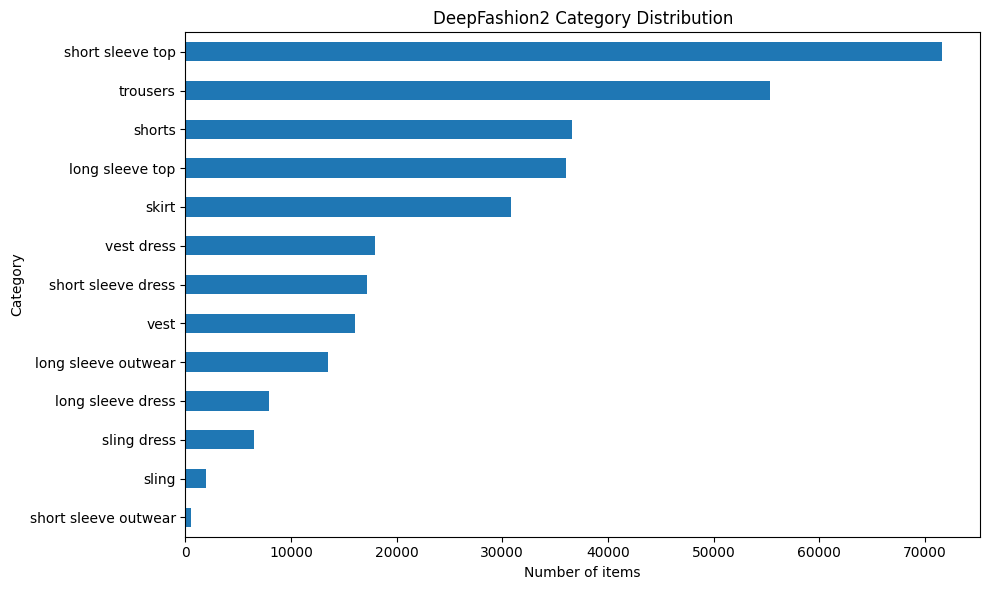

,percentage
category_name,
short sleeve top,22.95
trousers,17.74
shorts,11.73
long sleeve top,11.55
skirt,9.88
vest dress,5.75
short sleeve dress,5.51
vest,5.16
long sleeve outwear,4.31


In [16]:
category_col = detected["category"]

if category_col is None:
    print("No category column was detected.")
else:
    category_counts = df[category_col].value_counts(dropna=False)

    display(category_counts.to_frame("count"))

    plt.figure(figsize=(10, 6))
    category_counts.sort_values().plot(kind="barh")
    plt.title("DeepFashion2 Category Distribution")
    plt.xlabel("Number of items")
    plt.ylabel("Category")
    plt.tight_layout()
    plt.show()

    category_percent = (
        df[category_col]
        .value_counts(normalize=True, dropna=False)
        .mul(100)
        .round(2)
    )

    display(category_percent.to_frame("percentage"))


## Source distribution

DeepFashion2 includes different image sources such as shop/commercial and consumer/user imagery.

This is useful for evaluating whether retrieval behaves differently across image styles.


In [17]:
source_col = detected["source"]

if source_col is None:
    print("No source column was detected.")
else:
    source_counts = df[source_col].value_counts(dropna=False)
    display(source_counts.to_frame("count"))

    plt.figure(figsize=(6, 4))
    source_counts.plot(kind="bar")
    plt.title("Image Source Distribution")
    plt.xlabel("Source")
    plt.ylabel("Number of items")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()


No source column was detected.


## Scale, occlusion and viewpoint

These are important DeepFashion2 annotation properties.

We inspect them rather than automatically deleting difficult examples.


--- SCALE ---


,count
scale,
2,157021
1,78735
3,76430


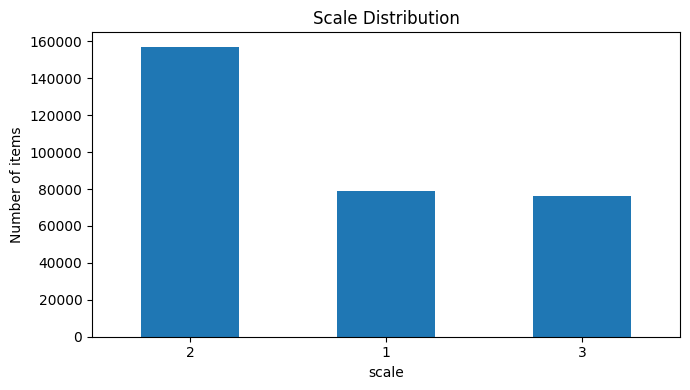

--- OCCLUSION ---


,count
occlusion,
2,147102
1,145379
3,19705


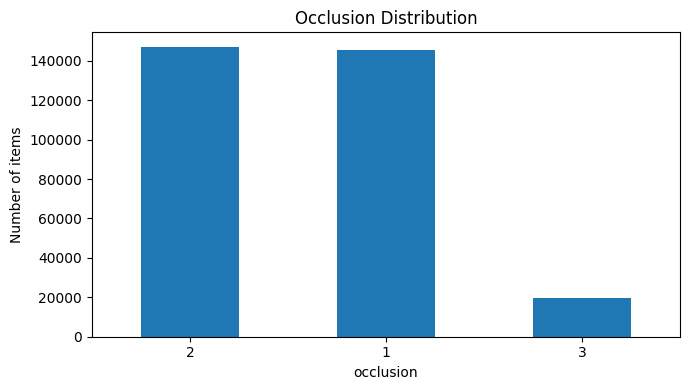

--- VIEWPOINT ---


,count
viewpoint,
2,244459
3,45052
1,22675


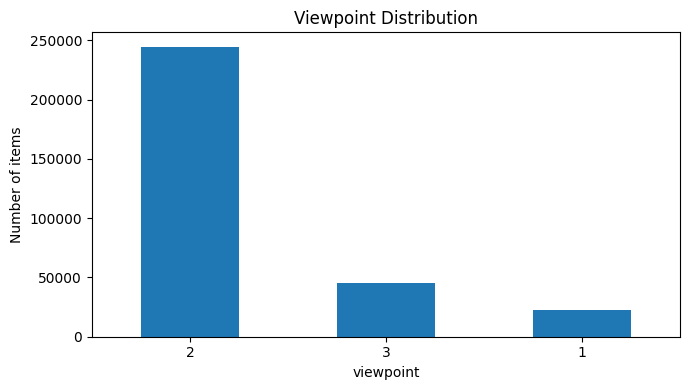

In [18]:
def analyze_categorical_column(field_name, title):
    col = detected[field_name]

    if col is None:
        print(f"{field_name}: not detected")
        return

    counts = df[col].value_counts(dropna=False)

    print(f"--- {field_name.upper()} ---")
    display(counts.to_frame("count"))

    plt.figure(figsize=(7, 4))
    counts.plot(kind="bar")
    plt.title(title)
    plt.xlabel(field_name)
    plt.ylabel("Number of items")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()


analyze_categorical_column("scale", "Scale Distribution")
analyze_categorical_column("occlusion", "Occlusion Distribution")
analyze_categorical_column("viewpoint", "Viewpoint Distribution")


# PART C — BOUNDING BOX ANALYSIS

Your project needs garment-level retrieval.

The PRD therefore uses the DeepFashion2 bounding box to crop each clothing item before sending it through CLIP.

We first inspect the bounding-box information in the exact dataframe.


In [19]:
# Detect common separate bbox columns

bbox_candidates = {
    "x1": ["x1", "xmin", "left", "bbox_x1", "bbox_left"],
    "y1": ["y1", "ymin", "top", "bbox_y1", "bbox_top"],
    "x2": ["x2", "xmax", "right", "bbox_x2", "bbox_right"],
    "y2": ["y2", "ymax", "bottom", "bbox_y2", "bbox_bottom"],
}

bbox_columns = {
    key: find_column(df.columns, candidates)
    for key, candidates in bbox_candidates.items()
}

bbox_single = find_column(
    df.columns,
    ["bbox", "bounding_box", "boundingbox", "box"]
)

print("Separate bbox columns:")
for key, value in bbox_columns.items():
    print(f"{key}: {value}")

print()
print("Single bbox column:", bbox_single)


Separate bbox columns:
x1: None
y1: None
x2: None
y2: None

Single bbox column: b_box


### If the dataset stores bbox information inside one column

We parse common formats such as:

```text
[10, 20, 300, 500]
```

or:

```text
10,20,300,500
```


In [20]:
def parse_bbox(value):
    if pd.isna(value):
        return [np.nan, np.nan, np.nan, np.nan]

    if isinstance(value, (list, tuple, np.ndarray)):
        values = list(value)
    else:
        try:
            values = ast.literal_eval(str(value))
        except Exception:
            values = re.findall(
                r"-?\d+(?:\.\d+)?",
                str(value)
            )

    try:
        values = list(values)
        if len(values) >= 4:
            return [
                float(values[0]),
                float(values[1]),
                float(values[2]),
                float(values[3])
            ]
    except Exception:
        pass

    return [np.nan, np.nan, np.nan, np.nan]


clean_df = df.copy()

if all(v is not None for v in bbox_columns.values()):
    clean_df["bbox_x1"] = pd.to_numeric(
        clean_df[bbox_columns["x1"]], errors="coerce"
    )
    clean_df["bbox_y1"] = pd.to_numeric(
        clean_df[bbox_columns["y1"]], errors="coerce"
    )
    clean_df["bbox_x2"] = pd.to_numeric(
        clean_df[bbox_columns["x2"]], errors="coerce"
    )
    clean_df["bbox_y2"] = pd.to_numeric(
        clean_df[bbox_columns["y2"]], errors="coerce"
    )

elif bbox_single is not None:
    parsed = clean_df[bbox_single].apply(parse_bbox)

    clean_df[
        ["bbox_x1", "bbox_y1", "bbox_x2", "bbox_y2"]
    ] = pd.DataFrame(
        parsed.tolist(),
        index=clean_df.index
    )

else:
    print("No bbox representation was detected.")

print("Bounding-box columns created where possible.")


Bounding-box columns created where possible.


In [21]:
# Bounding-box quality

bbox_ready = all(
    c in clean_df.columns
    for c in [
        "bbox_x1",
        "bbox_y1",
        "bbox_x2",
        "bbox_y2"
    ]
)

if bbox_ready:
    clean_df["bbox_width"] = (
        clean_df["bbox_x2"] -
        clean_df["bbox_x1"]
    )

    clean_df["bbox_height"] = (
        clean_df["bbox_y2"] -
        clean_df["bbox_y1"]
    )

    clean_df["bbox_area"] = (
        clean_df["bbox_width"] *
        clean_df["bbox_height"]
    )

    clean_df["invalid_bbox"] = (
        clean_df["bbox_x1"].isna()
        | clean_df["bbox_y1"].isna()
        | clean_df["bbox_x2"].isna()
        | clean_df["bbox_y2"].isna()
        | (clean_df["bbox_width"] <= 0)
        | (clean_df["bbox_height"] <= 0)
        | (clean_df["bbox_x1"] < 0)
        | (clean_df["bbox_y1"] < 0)
    )

    print("Invalid bbox rows:", clean_df["invalid_bbox"].sum())
    print(
        "Invalid bbox percentage:",
        round(clean_df["invalid_bbox"].mean() * 100, 2),
        "%"
    )
else:
    print("BBox quality checks cannot run because bbox columns were not detected.")


Invalid bbox rows: 1
Invalid bbox percentage: 0.0 %


# PART D — IMAGE INFORMATION

We look for image dimensions in the dataframe first.

If the dataframe does not store dimensions, we can calculate them from the actual image files later.


In [22]:
width_col = find_column(
    clean_df.columns,
    ["image_width", "img_width", "width", "image_w"]
)

height_col = find_column(
    clean_df.columns,
    ["image_height", "img_height", "height", "image_h"]
)

print("Image width column:", width_col)
print("Image height column:", height_col)


Image width column: img_width
Image height column: img_height


In [23]:
if bbox_ready and width_col is not None and height_col is not None:
    clean_df["image_width"] = pd.to_numeric(
        clean_df[width_col], errors="coerce"
    )

    clean_df["image_height"] = pd.to_numeric(
        clean_df[height_col], errors="coerce"
    )

    clean_df["image_area"] = (
        clean_df["image_width"] *
        clean_df["image_height"]
    )

    clean_df["bbox_area_ratio"] = (
        clean_df["bbox_area"] /
        clean_df["image_area"]
    )

    clean_df["bbox_aspect_ratio"] = (
        clean_df["bbox_width"] /
        clean_df["bbox_height"]
    )

    clean_df["image_aspect_ratio"] = (
        clean_df["image_width"] /
        clean_df["image_height"]
    )

    display(
        clean_df[
            [
                "bbox_width",
                "bbox_height",
                "bbox_area",
                "bbox_area_ratio",
                "bbox_aspect_ratio",
                "image_aspect_ratio"
            ]
        ].describe().T
    )
else:
    print(
        "Image dimensions were not available as dataframe columns."
    )


,count,mean,std,min,25%,50%,75%,max
bbox_width,312186.0,293.732771,121.761022,0.000000,201.000000,275.000000,378.000000,1.048000e+03
bbox_height,312186.0,356.952996,169.097887,0.000000,225.000000,330.000000,468.000000,1.319000e+03
bbox_area,312186.0,117908.512428,94792.233653,0.000000,48048.000000,89572.500000,163450.000000,1.158082e+06
bbox_area_ratio,312186.0,0.281904,0.247433,0.000000,0.099369,0.185098,0.392777,9.973975e-01
bbox_aspect_ratio,312185.0,0.920916,0.413261,0.082746,0.662873,0.859307,1.083770,8.025000e+00
image_aspect_ratio,312186.0,0.832923,0.252267,0.234095,0.666667,0.750000,0.977052,2.543478e+00


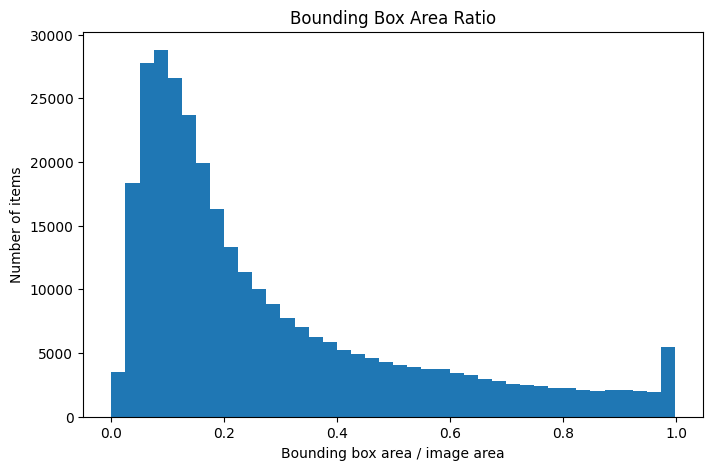

Mean: 0.2819
Median: 0.1851
Minimum: 0.0
Maximum: 0.9974


In [24]:
# Plot bbox area ratio if available

if "bbox_area_ratio" in clean_df.columns:
    ratio = (
        clean_df["bbox_area_ratio"]
        .replace([np.inf, -np.inf], np.nan)
        .dropna()
    )

    plt.figure(figsize=(8, 5))
    plt.hist(ratio, bins=40)
    plt.title("Bounding Box Area Ratio")
    plt.xlabel("Bounding box area / image area")
    plt.ylabel("Number of items")
    plt.show()

    print("Mean:", round(ratio.mean(), 4))
    print("Median:", round(ratio.median(), 4))
    print("Minimum:", round(ratio.min(), 4))
    print("Maximum:", round(ratio.max(), 4))
else:
    print("bbox_area_ratio is not available.")


# PART E — DATA CLEANING

We use conservative cleaning.

### We remove:
- exact duplicate rows
- missing essential item/category information
- invalid bounding boxes when bbox information is available

### We do NOT automatically remove:
- consumer images
- side/back views
- occluded clothing
- rare categories

Those variations are useful for a real visual-search system.


In [25]:
# Remove exact duplicate rows

before = len(clean_df)

clean_df = clean_df.drop_duplicates().copy()

print("Duplicate rows removed:", before - len(clean_df))
print("Rows remaining:", len(clean_df))


Duplicate rows removed: 0
Rows remaining: 312186


In [26]:
# Remove rows missing essential fields

essential_columns = []

for key in ["item_id", "category"]:
    col = detected.get(key)
    if col is not None:
        essential_columns.append(col)

if essential_columns:
    before = len(clean_df)

    clean_df = clean_df.dropna(
        subset=essential_columns
    ).copy()

    print(
        "Rows removed because essential fields were missing:",
        before - len(clean_df)
    )
else:
    print(
        "No item_id/category columns were automatically detected."
    )


Rows removed because essential fields were missing: 0


In [27]:
# Remove invalid bounding boxes

if "invalid_bbox" in clean_df.columns:
    before = len(clean_df)

    clean_df = clean_df[
        ~clean_df["invalid_bbox"]
    ].copy()

    print(
        "Invalid bbox rows removed:",
        before - len(clean_df)
    )
else:
    print("No bbox cleaning was performed.")


Invalid bbox rows removed: 1


## Standardize category names

This creates a clean category field without destroying the original category column.


In [28]:
category_col = detected["category"]

if category_col is not None:
    clean_df["category_clean"] = (
        clean_df[category_col]
        .astype(str)
        .str.strip()
        .str.lower()
        .str.replace(
            r"[^a-z0-9]+",
            "_",
            regex=True
        )
        .str.strip("_")
    )

    display(
        clean_df[
            [category_col, "category_clean"]
        ]
        .drop_duplicates()
        .head(30)
    )
else:
    print("Category column not found.")


,category_name,category_clean
0,long sleeve outwear,long_sleeve_outwear
1,trousers,trousers
2,short sleeve top,short_sleeve_top
3,skirt,skirt
4,short sleeve dress,short_sleeve_dress
5,shorts,shorts
6,vest,vest
7,vest dress,vest_dress
11,long sleeve top,long_sleeve_top
18,long sleeve dress,long_sleeve_dress


# PART F — FEATURE ENGINEERING

For your CLIP-based project, we do **not** need to create hundreds of handcrafted image features.

We create a small set of useful, explainable metadata features.

### Derived features

- `bbox_width`
- `bbox_height`
- `bbox_area`
- `bbox_aspect_ratio`
- `bbox_area_ratio`
- `image_aspect_ratio`

### Dataset metadata

- category
- source
- scale
- occlusion
- viewpoint
- pair/style information

### Main learned feature later

CLIP will generate the **512-dimensional visual-semantic embedding**.

That embedding is the main feature used for FAISS retrieval.


In [29]:
# Feature summary

feature_columns = [
    "bbox_width",
    "bbox_height",
    "bbox_area",
    "bbox_aspect_ratio",
    "bbox_area_ratio",
    "image_aspect_ratio",
]

available_features = [
    c for c in feature_columns
    if c in clean_df.columns
]

print("Available engineered features:")
for feature in available_features:
    print("✓", feature)

if available_features:
    display(
        clean_df[available_features]
        .describe()
        .T
    )


Available engineered features:
✓ bbox_width
✓ bbox_height
✓ bbox_area
✓ bbox_aspect_ratio
✓ bbox_area_ratio
✓ image_aspect_ratio


,count,mean,std,min,25%,50%,75%,max
bbox_width,312185.0,293.733712,121.760083,8.000000,201.000000,275.000000,378.000000,1.048000e+03
bbox_height,312185.0,356.954139,169.096951,20.000000,225.000000,330.000000,468.000000,1.319000e+03
bbox_area,312185.0,117908.890116,94792.150576,176.000000,48048.000000,89573.000000,163450.000000,1.158082e+06
bbox_aspect_ratio,312185.0,0.920916,0.413261,0.082746,0.662873,0.859307,1.083770,8.025000e+00
bbox_area_ratio,312185.0,0.281905,0.247433,0.000470,0.099370,0.185098,0.392778,9.973975e-01
image_aspect_ratio,312185.0,0.832922,0.252267,0.234095,0.666667,0.750000,0.977058,2.543478e+00


# PART G — IMAGE FILE CHECK

If the dataframe contains image paths/names, we check whether the corresponding image files exist in the downloaded Kaggle dataset.

This is an important cleaning step before CLIP.


In [30]:
image_path_col = detected["image_path"]

print("Detected image column:", image_path_col)

if image_path_col is not None:
    display(
        clean_df[
            [image_path_col]
        ].head(10)
    )
else:
    print(
        "No image path column was detected automatically."
    )


Detected image column: path


,path
0,/kaggle/input/deepfashion2-original-with-dataframes/DeepFashion2/deepfashion2_original_images/tr...
1,/kaggle/input/deepfashion2-original-with-dataframes/DeepFashion2/deepfashion2_original_images/tr...
2,/kaggle/input/deepfashion2-original-with-dataframes/DeepFashion2/deepfashion2_original_images/tr...
3,/kaggle/input/deepfashion2-original-with-dataframes/DeepFashion2/deepfashion2_original_images/tr...
4,/kaggle/input/deepfashion2-original-with-dataframes/DeepFashion2/deepfashion2_original_images/tr...
5,/kaggle/input/deepfashion2-original-with-dataframes/DeepFashion2/deepfashion2_original_images/tr...
6,/kaggle/input/deepfashion2-original-with-dataframes/DeepFashion2/deepfashion2_original_images/tr...
7,/kaggle/input/deepfashion2-original-with-dataframes/DeepFashion2/deepfashion2_original_images/tr...
8,/kaggle/input/deepfashion2-original-with-dataframes/DeepFashion2/deepfashion2_original_images/tr...
9,/kaggle/input/deepfashion2-original-with-dataframes/DeepFashion2/deepfashion2_original_images/tr...


In [32]:
# Resolve image paths inside the EXACT Kaggle dataset

def resolve_image_path(value):
    if pd.isna(value):
        return None

    value = str(value)

    # Direct path
    if os.path.isfile(value):
        return value

    # Relative to the exact Kaggle dataset
    candidate = os.path.join(DATASET_PATH, value)
    if os.path.isfile(candidate):
        return candidate

    # Search by basename
    basename = os.path.basename(value)

    matches = [
        f for f in all_files
        if os.path.basename(f) == basename
    ]

    if matches:
        return matches[0]

    return None


if image_path_col is not None:
    # Start with 5,000 rows so this does not take too long.
    n_check = min(5000, len(clean_df))

    resolved = (
        clean_df[image_path_col]
        .head(n_check)
        .apply(resolve_image_path)
    )

    print("Checked:", n_check)
    print("Images found:", resolved.notna().sum())
    print("Images missing:", resolved.isna().sum())
    print(
        "Found percentage:",
        round(resolved.notna().mean() * 100, 2),
        "%"
    )
else:
    print("Image path check skipped.")


Checked: 5000
Images found: 5000
Images missing: 0
Found percentage: 100.0 %


# PART H — CATEGORY-BALANCED WORKING SUBSET

Your PRD targets a reproducible working subset of approximately **50,000 item crops**.

During development, start smaller:

```text
5,000 → test
10,000 → test
50,000 → final working subset
```

This notebook uses a simple category-balanced sampling strategy.


In [33]:
# Start small during development.
# Change to 50000 for the final target.

TARGET_ITEMS = 5000

if "category_clean" not in clean_df.columns:
    working_df = clean_df.copy()
    print("category_clean is unavailable.")
else:
    category_data = clean_df.dropna(
        subset=["category_clean"]
    ).copy()

    categories = sorted(
        category_data["category_clean"].unique()
    )

    per_category = max(
        1,
        TARGET_ITEMS // len(categories)
    )

    parts = []

    for category in categories:
        rows = category_data[
            category_data["category_clean"] == category
        ]

        n = min(
            per_category,
            len(rows)
        )

        if n > 0:
            parts.append(
                rows.sample(
                    n=n,
                    random_state=42
                )
            )

    if parts:
        working_df = pd.concat(
            parts,
            ignore_index=True
        )
    else:
        working_df = pd.DataFrame(
            columns=clean_df.columns
        )

    working_df = working_df.sample(
        frac=1,
        random_state=42
    ).reset_index(drop=True)

print("Working subset size:", len(working_df))


Working subset size: 4992


,count
category_clean,
long_sleeve_outwear,384
vest_dress,384
sling_dress,384
short_sleeve_outwear,384
shorts,384
short_sleeve_top,384
sling,384
skirt,384
long_sleeve_dress,384


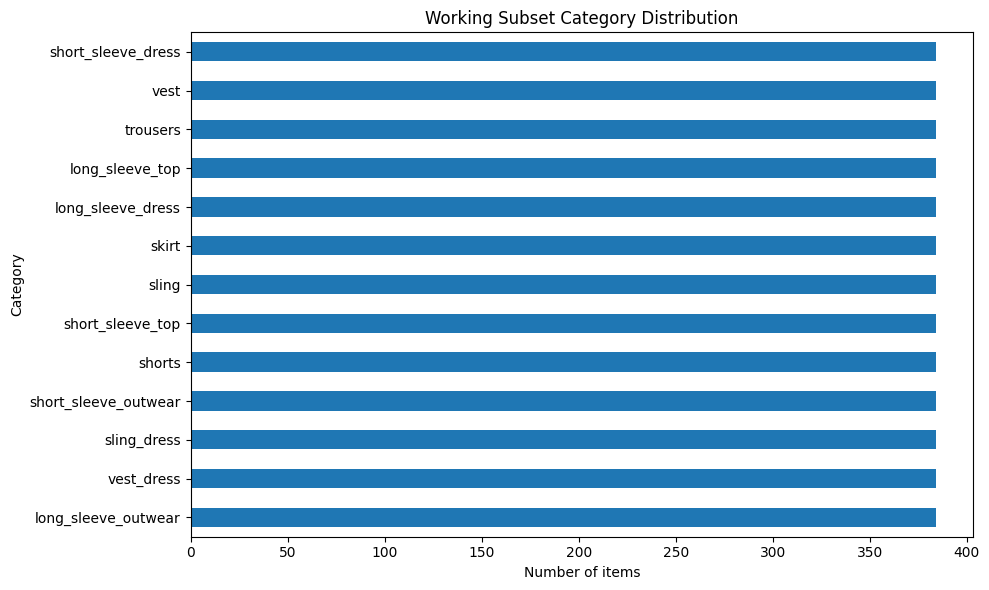

In [34]:
# Working subset category distribution

if "category_clean" in working_df.columns:
    subset_counts = (
        working_df["category_clean"]
        .value_counts()
    )

    display(
        subset_counts.to_frame("count")
    )

    plt.figure(figsize=(10, 6))
    subset_counts.sort_values().plot(
        kind="barh"
    )
    plt.title(
        "Working Subset Category Distribution"
    )
    plt.xlabel("Number of items")
    plt.ylabel("Category")
    plt.tight_layout()
    plt.show()


# PART I — FINAL DATA QUALITY REPORT


In [35]:
# Final report

report = {
    "Original rows": len(df),
    "Cleaned rows": len(clean_df),
    "Rows removed": len(df) - len(clean_df),
    "Removal percentage": round(
        (len(df) - len(clean_df)) / len(df) * 100,
        2
    ),
    "Working subset rows": len(working_df),
}

display(
    pd.DataFrame(
        report.items(),
        columns=["Metric", "Value"]
    )
)


,Metric,Value
0,Original rows,312186.0
1,Cleaned rows,312185.0
2,Rows removed,1.0
3,Removal percentage,0.0
4,Working subset rows,4992.0


In [36]:
# Remaining missing values

remaining_missing = (
    clean_df
    .isnull()
    .sum()
    .sort_values(ascending=False)
)

display(
    remaining_missing[
        remaining_missing > 0
    ].to_frame("remaining_missing")
)


,remaining_missing


# PART J — SAVE THE CLEAN DATA

We save:

1. the complete cleaned metadata
2. the smaller working subset

These files can be used by the next notebook for garment cropping and CLIP embeddings.


In [37]:
OUTPUT_FOLDER = os.path.join(
    DATASET_PATH,
    "processed_project_data"
)

os.makedirs(
    OUTPUT_FOLDER,
    exist_ok=True
)

clean_output = os.path.join(
    OUTPUT_FOLDER,
    "deepfashion2_clean_metadata.csv"
)

subset_output = os.path.join(
    OUTPUT_FOLDER,
    "deepfashion2_working_subset.csv"
)

clean_df.to_csv(
    clean_output,
    index=False
)

working_df.to_csv(
    subset_output,
    index=False
)

print("Saved cleaned metadata:")
print(clean_output)
print()
print("Saved working subset:")
print(subset_output)


Saved cleaned metadata:
/root/.cache/kagglehub/datasets/thusharanair/deepfashion2-original-with-dataframes/versions/2/processed_project_data/deepfashion2_clean_metadata.csv

Saved working subset:
/root/.cache/kagglehub/datasets/thusharanair/deepfashion2-original-with-dataframes/versions/2/processed_project_data/deepfashion2_working_subset.csv


# PART K — VISUAL SANITY CHECK

This tries to display a few real images from the **exact downloaded Kaggle dataset**.

We want to visually confirm that:

- the image exists
- it opens correctly
- the category roughly matches the image


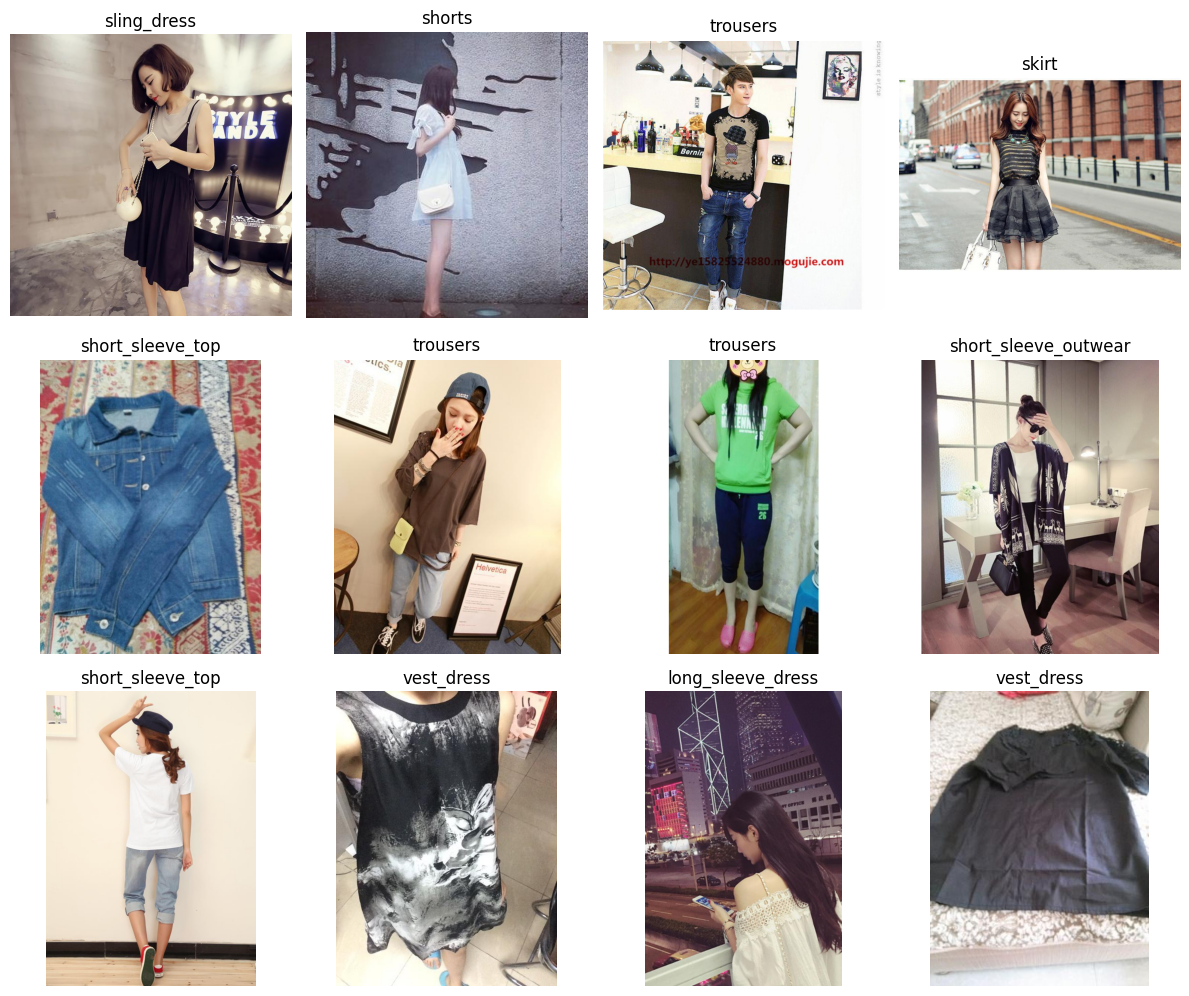

In [38]:
if image_path_col is not None and len(working_df) > 0:
    sample = working_df.sample(
        n=min(12, len(working_df)),
        random_state=42
    ).copy()

    sample["resolved_image"] = (
        sample[image_path_col]
        .apply(resolve_image_path)
    )

    sample = sample[
        sample["resolved_image"].notna()
    ]

    if len(sample) == 0:
        print(
            "No image files could be resolved. "
            "Check the image path column."
        )
    else:
        fig, axes = plt.subplots(
            3,
            4,
            figsize=(12, 10)
        )

        axes = axes.flatten()

        for ax in axes:
            ax.axis("off")

        for ax, (_, row) in zip(
            axes,
            sample.iterrows()
        ):
            try:
                img = Image.open(
                    row["resolved_image"]
                )

                ax.imshow(img)

                label = row.get(
                    "category_clean",
                    "unknown"
                )

                ax.set_title(
                    str(label)
                )

                ax.axis("off")
            except Exception:
                ax.axis("off")

        plt.tight_layout()
        plt.show()
else:
    print(
        "Visual check skipped because no image-path column was detected."
    )
